# GAN Intrusion Detection

Progetto del corso Sicurezza delle Architetture Orientate ai Servizi · Università degli Studi di Milano · ottobre 2025<br>
Autori: Gaetano Angelo Alberto Loizzo, Michele Vulpio

Una GAN condizionale genera sequenze di chiamate di sistema di attacco a partire dal dataset ADFA-LD. Le sequenze sintetiche vengono aggiunte al solo training set per bilanciare le classi, e un classificatore GCN viene addestrato con e senza di esse. Risultati e analisi sono nel [README del repository](https://github.com/GaetanoAA/GAN_Intrusion_Detection#readme).

Il notebook parte da `train_evaluate_models.ipynb` del template [gweldit/VanillaGAN](https://github.com/gweldit/VanillaGAN) (versione di giugno 2024), che fornisce anche i moduli importati più avanti. Il template è distribuito con licenza Apache 2.0 (copia in `third_party/`); le modifiche sono elencate nel README.

**Per eseguirlo su Colab** (runtime con GPU): scarica ADFA-LD dalla [pagina ufficiale UNSW](https://research.unsw.edu.au/projects/adfa-ids-datasets), carica in `/content` uno zip `ADFA-LD.zip` che contenga la cartella `ADFA-LD` con `Training_Data_Master`, `Validation_Data_Master` e `Attack_Data_Master`, poi esegui tutte le celle.

# Setting dell'Ambiente di Lavoro

In [102]:
!git clone https://github.com/gweldit/VanillaGAN
!git -C VanillaGAN checkout -q 0aa64f9  # versione del template usata nell'esecuzione (aprile 2025)

Cloning into 'VanillaGAN'...
remote: Enumerating objects: 83, done.
remote: Counting objects: 100% (83/83), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 83 (delta 40), reused 52 (delta 16), pack-reused 0 (from 0)
Receiving objects: 100% (83/83), 1.66 MiB | 5.51 MiB/s, done.
Resolving deltas: 100% (40/40), done.


In [103]:
!pip install -r /content/VanillaGAN/requirements.txt

In [105]:
%cd /content/VanillaGAN

/content/VanillaGAN


In [106]:
import networkx as nx
import matplotlib.pyplot as plt
import torch
import numpy as np
from collections import Counter
from torch_geometric.loader import DataLoader
import torch.nn as nn
from torch.optim import Adam
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import train_test_split

from pathlib import Path
import os

# custom modules
from models import Generator, Discriminator
from custom_dataset import CustomSequenceDataset
from preprocess_data import read_adfa_data, sequence_to_graph, fetch_graph_data
from utils import get_device, plot_loss_curve, evaluate_gcn_model
from classifiers import GCNModel
from train import train_gan_model
from train import train_gcn_model
from models import init_weights

In [107]:
# for reproducibility
import random

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

## Read, Preprocess, e Fetch the ADFA datasets


In [108]:
data_folder = "ADFA-LD"
current_directory = Path(os.getcwd())
parent_path = current_directory.parent.absolute()

full_data_folder_path = os.path.join(parent_path, data_folder)

In [ ]:
# 1) estrai lo zip
!rm -rf /content/ADFA-LD
!unzip -q "/content/ADFA-LD.zip" -d /content/

# 2) se lo zip crea sottocartelle (es. ADFA-IDS_DATASETS/ADFA-LD), sposta/rinomina
import os, glob, shutil

# cerca una cartella che contenga le tre sottocartelle richieste
candidates = [p for p in glob.glob("/content/**/ADFA-LD", recursive=True) if os.path.isdir(p)]
if candidates:
    src = candidates[0]
    if src != "/content/ADFA-LD":
        shutil.move(src, "/content/ADFA-LD")
else:
    # piano B: trova la cartella che contiene Training_Data_Master
    tdm = [p for p in glob.glob("/content/**/Training_Data_Master", recursive=True) if os.path.isdir(p)]
    if tdm:
        src = os.path.dirname(tdm[0])
        if os.path.basename(src) != "ADFA-LD":
            shutil.move(src, "/content/ADFA-LD")

# 3) verifica struttura
ok = []
for sub in ["Training_Data_Master","Validation_Data_Master","Attack_Data_Master"]:
    path = f"/content/ADFA-LD/{sub}"
    ok.append(os.path.exists(path))
    print(sub, "->", os.path.exists(path))
if all(ok):
    print("\nTutto ok: il codice troverà il dataset in /content/ADFA-LD ✅")
    print("Esempio file:", os.listdir("/content/ADFA-LD/Training_Data_Master")[:5])
else:
    print("\n⚠️ Struttura non completa. Controlla che lo zip contenga le tre cartelle richieste.")


In [110]:
adfa_sub_folders = [
    "Training_Data_Master",
    "Validation_Data_Master",
    "Attack_Data_Master",
]

benign_training_data_path = os.path.join(full_data_folder_path, adfa_sub_folders[0])
benign_validation_data_path = os.path.join(full_data_folder_path, adfa_sub_folders[1])

attack_data_path = os.path.join(full_data_folder_path, adfa_sub_folders[2])


# read the sub folders
benign_train_sequences, benign_train_labels = read_adfa_data(benign_training_data_path)

benign_val_sequences, benign_val_labels = read_adfa_data(benign_validation_data_path)

attack_sequences, attack_labels = read_adfa_data(attack_data_path)


data = benign_train_sequences + benign_val_sequences + attack_sequences
labels = benign_train_labels + benign_val_labels + attack_labels

# perform  70 % training and 30% testing set split

train_data, test_data, train_labels, test_labels = train_test_split(
    data, labels, test_size=0.3, random_state=42, shuffle=True, stratify=labels
)

len(train_data), len(train_labels), len(test_data), len(test_labels)

Read 833 sequences from Training_Data_Master
Read 4372 sequences from Validation_Data_Master
Read 746 sequences from Attack_Data_Master


(4165, 4165, 1786, 1786)

In [111]:
len(attack_sequences)

746

In [112]:
# Data is imbalanced: 3643 benign & 522 attack (malicious) sequences will be used for training the GCN model
Counter(train_labels)

Counter({0: 3643, 1: 522})

In [113]:
Counter(test_labels)

Counter({0: 1562, 1: 224})

In [114]:
# Create a custom dataset
batch_size = 64
# convert train_data sequences and val_data sequences into graphs

train_graph_dataset = fetch_graph_data(train_data, train_labels)
val_graph_dataset = fetch_graph_data(test_data, test_labels)


# Create a data loader
graph_train_loader = DataLoader(
    train_graph_dataset, batch_size=batch_size, shuffle=True
)
graph_val_loader = DataLoader(val_graph_dataset, batch_size=batch_size, shuffle=False)

In [115]:
# you can see the graph data: it has edge_index, weight, num_nodes, y (label of the graph, i.e., malign or benign), and x (node features). Here, x is a list of integers representing the node features. They need to be converted to a one-hot vector of size vocab_size or vector of embedded representation.
train_graph_dataset[0]

Data(edge_index=[2, 23], weight=[23], num_nodes=10, x=[1], y=0)

In [116]:
# device = get_device()
vocab_size = 342
hidden_dim = 128  # also the number of hidden nodes in the GCN. Can be set to 128, 256 or 512. If you have more GPU, you can increase it. However, you may face overfitting. Increase dropout if you face overfitting. Like dropout = 0.6, 0.7, 0.8
num_classes = 2
dropout = 0.4
output_dim = num_classes
# number of GCN layers, depending on your GPU, set it to any integer from 2 to 5.
num_layers = 3
EPOCHS_GCN = 35


device = torch.device("cuda")


gcn_model = GCNModel(
    in_channels=vocab_size,
    hidden_channels=hidden_dim,
    out_channels=num_classes,
    num_layers=num_layers,
    dropout=dropout,
).to(device)

train_losses, train_f1_scores = train_gcn_model(
    gcn_model,
    graph_train_loader,
    vocab_size=vocab_size,
    epochs=EPOCHS_GCN,
    device=device,
)

100%|██████████| 66/66 [00:00<00:00, 72.34it/s]


Epoch 1 / 35, Loss: 0.4669, F1 Score: 0.0000


100%|██████████| 66/66 [00:00<00:00, 76.90it/s]


Epoch 2 / 35, Loss: 0.4132, F1 Score: 0.3788


100%|██████████| 66/66 [00:00<00:00, 77.87it/s]


Epoch 3 / 35, Loss: 0.4038, F1 Score: 0.4655


... (60 outputs left out)

100%|██████████| 66/66 [00:00<00:00, 84.75it/s]


Epoch 34 / 35, Loss: 0.3601, F1 Score: 0.7638


100%|██████████| 66/66 [00:00<00:00, 90.13it/s]

Epoch 35 / 35, Loss: 0.3629, F1 Score: 0.8024


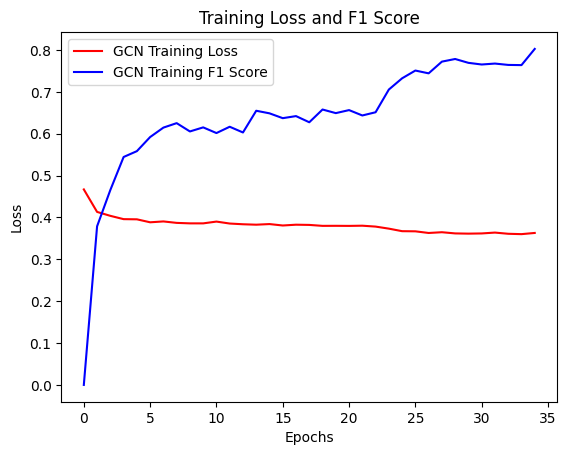

In [117]:
x = np.arange(EPOCHS_GCN, dtype=int)
plt.plot(x, train_losses, color="red", label="GCN Training Loss")
plt.plot(x, train_f1_scores, color="blue", label="GCN Training F1 Score")
plt.title("Training Loss and F1 Score")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [118]:
evaluate_gcn_model(gcn_model, graph_val_loader, vocab_size=vocab_size, device=device)

GCN performance:
Accuracy: 0.9485
Precision: 0.8903
Recall: 0.8692
F1 score: 0.8794
MCC: 0.7592


In [119]:
# PREPARE DATASET FOR GAN MODEL: pad the sequences to make them of same length, then trim them to a fixed sequence length to avoid too much padding.
# convert train_data sequences and val_data sequences into graphs
SEQUENCE_LENGTH = 100
train_data_padded = pad_sequence(
    [torch.tensor(sequence, dtype=torch.long) for sequence in train_data],
    batch_first=True,
)
val_data_padded = pad_sequence(
    [torch.tensor(sequence, dtype=torch.long) for sequence in test_data],
    batch_first=True,
)

train_data_padded.shape, val_data_padded.shape

(torch.Size([4165, 4494]), torch.Size([1786, 3666]))

In [120]:
train_data_padded[:, SEQUENCE_LENGTH].shape, val_data_padded[:SEQUENCE_LENGTH].shape

# our dataset will be of shape (n_samples, SEQUENCE_LENGTH).
train_dataset = CustomSequenceDataset(
    train_data_padded[:, :SEQUENCE_LENGTH], train_labels
)
val_dataset = CustomSequenceDataset(val_data_padded[:, :SEQUENCE_LENGTH], test_labels)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [121]:
# hyperparameters of the generator and discriminator of the GAN model
latent_dim = 100
hidden_dim = 128
vocab_size = 342  # we have 342 unique system calls in the ADFA dataset
seq_len = SEQUENCE_LENGTH  # sequence length of the ADFA dataset with less than 120, will be padded. If sequence is longer than 120, it will be truncated.
output_dim = vocab_size
embed_dim = 10
dropout = 0.5
batch_size = 32
#n_samples = 4459  # pareggerebbe le classi sull'intero dataset (5205 benigni - 746 attacchi)
n_samples = 3121  # pareggia le classi nel training set (3643 benigni - 522 attacchi)
num_classes = 2
lr = 5e-5  # 2e-6
epochs = 150
# criterion = nn.BCELoss()
criterion = nn.CrossEntropyLoss()
device = get_device()
temperature = 0.2  # 0.1

gen = Generator(
    latent_dim,
    seq_len,
    hidden_dim,
    output_dim,
    embed_dim,
    dropout,
    conditional_info=True,
    num_classes=num_classes,
).to(device)
# gen = Gen(latent_dim, hidden_dim, seq_len, output_dim, embed_dim, dropout).to(device)

disc = Discriminator(
    vocab_size,
    seq_len,
    hidden_dim,
    embed_dim,
    dropout,
    conditional_info=True,
    num_classes=num_classes,
).to(device)


# Apply the weights initialization to your GAN model, uncomment the two lines of code below:

#gen.apply(init_weights)
#disc.apply(init_weights)

gen_optimizer = Adam(gen.parameters(), lr=lr, betas=(0.5, 0.999))

disc_optimizer = Adam(disc.parameters(), lr=lr, betas=(0.5, 0.999))

In [122]:
device = get_device()

In [123]:
# input_data = torch.randint(0, vocab_size, (n_samples, seq_len))
# input_labels = torch.randint(0, num_classes, (n_samples,))
# train_dataset = CustomSequenceDataset(input_data, input_labels)
# train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

In [124]:
# note that the temperature is set to any value between 0 and 1.
g_losses, d_losses = train_gan_model(
    gen,
    disc,
    gen_optimizer,
    disc_optimizer,
    train_loader,
    epochs,
    vocab_size,
    device=device,
    tau=temperature,
)

Epoch 1 / 150


100%|██████████| 66/66 [00:00<00:00, 92.84it/s]


D Loss: 1.3432, G Loss: 0.0000
Epoch 2 / 150


100%|██████████| 66/66 [00:00<00:00, 84.71it/s]


D Loss: 1.0214, G Loss: 0.0000
Epoch 3 / 150


100%|██████████| 66/66 [00:00<00:00, 87.86it/s]


... (291 outputs left out)

100%|██████████| 66/66 [00:01<00:00, 59.96it/s]


D Loss: 0.0000, G Loss: -0.0000
Epoch 150 / 150


100%|██████████| 66/66 [00:01<00:00, 65.27it/s]

D Loss: 0.0000, G Loss: -0.0000


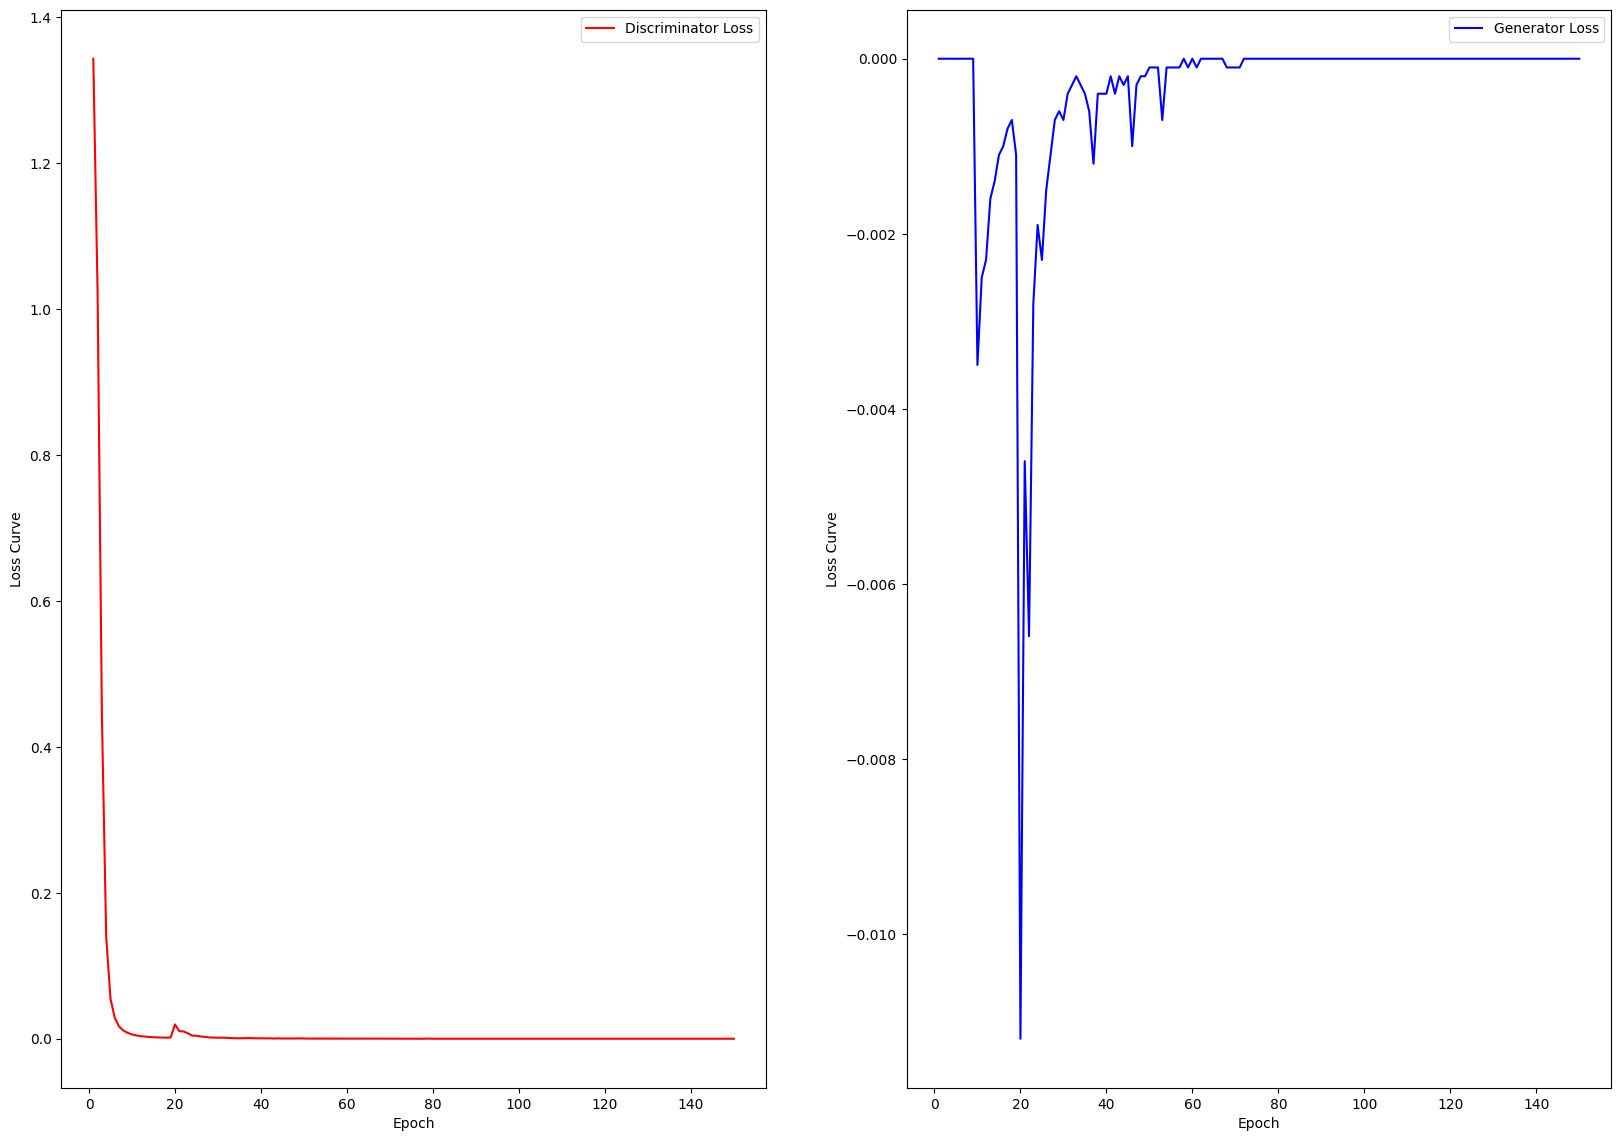

In [125]:
plot_loss_curve(d_losses, g_losses, epochs)

## generate fake samples


In [126]:
#fake_labels = torch.randint(0, num_classes, (n_samples,), dtype=torch.long)
fake_labels = torch.full((n_samples,), 1, dtype=torch.long)  # All labels are 1 (Per far generare solo attacchi)
z = torch.randn((n_samples, latent_dim))

# print("random noise shape", z.shape)
# set generator to eval mode
gen.eval()

fake_data = gen(z.to(device), fake_labels.to(device)).detach().cpu()

# print the generated data: if the data contains nan values, it means that there is gradient explosion, or other issues. To avoid such problems, change the termperature value to be between 0.1 and 0.5. Also, trying changing the learning rate to be between 5e-6 and 1e-4. Of course, this is just a suggestion. You might experiment with other values if you want, and report your findings.
print(fake_data)

tensor([[[1.6913e-08, 4.3182e-08, 2.6710e-06,  ..., 1.6234e-07,
          7.4093e-03, 2.6387e-07],
         [4.2410e-08, 4.7119e-08, 2.9180e-09,  ..., 6.6202e-07,
          7.1121e-10, 3.0991e-08],
         [2.1424e-08, 5.9625e-05, 1.0132e-07,  ..., 3.8230e-07,
          8.7326e-08, 1.3725e-06],
         ...,
         [2.6517e-02, 2.2515e-06, 1.4126e-09,  ..., 1.6533e-09,
          2.5685e-10, 4.9142e-09],
         [9.8593e-01, 1.2539e-08, 2.1083e-11,  ..., 6.1559e-12,
          2.3023e-11, 1.4031e-10],
         [6.5600e-06, 6.3651e-06, 4.5440e-10,  ..., 8.3718e-08,
          1.3410e-08, 1.6289e-07]],

        [[3.5894e-07, 3.1724e-07, 2.5084e-07,  ..., 5.8300e-07,
          3.8469e-08, 2.3358e-07],
         [9.7419e-09, 8.4961e-08, 3.5437e-09,  ..., 7.1616e-06,
          1.0631e-09, 1.2619e-08],
         [5.1253e-09, 1.4987e-07, 4.8891e-09,  ..., 5.3886e-07,
          1.6716e-07, 2.4938e-06],
         ...,
         [3.0522e-02, 4.4464e-06, 1.6333e-07,  ..., 1.0162e-10,
          1.420

In [127]:
print(fake_labels.shape)

torch.Size([3121])


In [128]:
# get the generated samples as tokens (this are a sequence tokens or words / characters, represented by integers .)
from pprint import pprint

fake_samples = torch.argmax(fake_data, dim=-1).cpu().numpy()

# now, let's see two generated sequences
pprint(fake_samples[:2])

array([[203,  13,  33,  33, 168,   5,   5,  33, 175, 162,  55, 192, 102,
        192, 221,  42,   3, 102,   6, 192,   6, 125,   6, 142, 197, 195,
         54, 102, 192, 120, 168, 175, 197, 175, 163, 195, 142, 192, 168,
        265, 265, 180,  85, 175,   5, 142,  45, 265, 168, 168,   3, 192,
          6, 105,  78, 175,   6, 252, 195, 174,   5, 301, 168, 140,  45,
        219, 162, 174, 195, 252,   5,  13,  85, 174,  33, 125,  78, 192,
        120, 102,   5,   3, 192,   6, 220, 174, 174, 221, 125,   6, 240,
          3, 192,   0, 175,   3, 102, 168,   0, 102],
       [265,  11, 240,  33, 168,   5, 102,  33, 175,   6,  13, 192, 102,
          6, 221, 265,   3,  33,   6,   3,   6, 125, 142, 197, 197,  33,
        221, 133, 252, 162, 174, 140, 174,   3,   6, 195, 240, 192, 168,
         13, 240, 180,  85, 175,   5, 114,  45,   3, 301, 327, 192, 192,
         83, 140,  33,  54,   6, 125, 196, 174,   5, 301,   5, 174, 114,
        195, 162, 102,   4,   3,   5, 174,  85, 174, 174, 174, 195, 19

# Generazione del grafico dai token generati

` Usando la funzione sequence_to_graph() trovata nel preprocess_data.py`


In [129]:
# convert the generated samples into a networkx graph and also pytorch_geometric graph data object
networkx_graph, pytorch_geometric_data = sequence_to_graph(fake_samples[0])

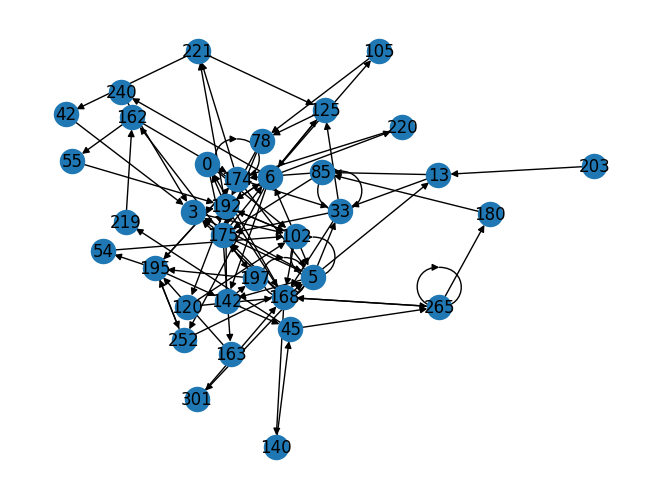

In [130]:
# you can see the networkx graph we generated
nx.draw(networkx_graph, with_labels=True)
plt.show()

# The Remaining Steps:

```
1 - generate many fake samples (sequences and their corresponding labels),[3121 attacchi finti, quanti servono per pareggiare
le classi nel training set: 3643 benigni contro 522 attacchi]

2 - add these fake sequences to train_data sequences, and add their fake_labels (benign or malign) to the trian_labels

3 - train a new GCNModel and compare performance before and after adding fake samples


```


# Aggiunta dei fake maligni generati dalla cGAN solo in train_data

In [131]:
data_1 = benign_train_sequences + benign_val_sequences + attack_sequences
labels_1 = benign_train_labels + benign_val_labels + attack_labels

# perform  70 % training and 30% testing set split

train_data_1, test_data_1, train_labels_1, test_labels_1 = train_test_split(
    data_1, labels_1, test_size=0.3, random_state=42, shuffle=True, stratify=labels_1
)
train_data_1 = train_data_1 + fake_samples.tolist()
train_labels_1 = train_labels_1 + fake_labels.tolist()

len(train_data_1), len(train_labels_1), len(test_data_1), len(test_labels_1)

(7286, 7286, 1786, 1786)

In [132]:
# Create a custom dataset
batch_size = 64
# convert train_data sequences and val_data sequences into graphs

train_graph_dataset_1 = fetch_graph_data(train_data_1, train_labels_1)
val_graph_dataset_1 = fetch_graph_data(test_data_1, test_labels_1)


# Create a data loader
graph_train_loader_1 = DataLoader(
    train_graph_dataset_1, batch_size=batch_size, shuffle=True
)
graph_val_loader_1 = DataLoader(val_graph_dataset_1, batch_size=batch_size, shuffle=False)

In [133]:
# you can see the graph data: it has edge_index, weight, num_nodes, y (label of the graph, i.e., malign or benign), and x (node features). Here, x is a list of integers representing the node features. They need to be converted to a one-hot vector of size vocab_size or vector of embedded representation.
train_graph_dataset_1[0]

Data(edge_index=[2, 23], weight=[23], num_nodes=10, x=[1], y=0)

In [134]:
# device = get_device()
vocab_size = 342
hidden_dim = 128  # also the number of hidden nodes in the GCN. Can be set to 128, 256 or 512. If you have more GPU, you can increase it. However, you may face overfitting. Increase dropout if you face overfitting. Like dropout = 0.6, 0.7, 0.8
num_classes = 2
dropout = 0.4
output_dim = num_classes
# number of GCN layers, depending on your GPU, set it to any integer from 2 to 5.
num_layers = 3
EPOCHS_GCN = 35


device = torch.device("cuda")


gcn_model = GCNModel(
    in_channels=vocab_size,
    hidden_channels=hidden_dim,
    out_channels=num_classes,
    num_layers=num_layers,
    dropout=dropout,
).to(device)

train_losses, train_f1_scores = train_gcn_model(
    gcn_model,
    graph_train_loader_1,
    vocab_size=vocab_size,
    epochs=EPOCHS_GCN,
    device=device,
)

100%|██████████| 114/114 [00:01<00:00, 81.69it/s]


Epoch 1 / 35, Loss: 0.4448, F1 Score: 0.7936


100%|██████████| 114/114 [00:01<00:00, 81.19it/s]


Epoch 2 / 35, Loss: 0.3633, F1 Score: 0.9495


100%|██████████| 114/114 [00:01<00:00, 82.66it/s]


Epoch 3 / 35, Loss: 0.3604, F1 Score: 0.9525


... (60 outputs left out)

100%|██████████| 114/114 [00:01<00:00, 74.48it/s]


Epoch 34 / 35, Loss: 0.3474, F1 Score: 0.9663


100%|██████████| 114/114 [00:01<00:00, 85.28it/s]

Epoch 35 / 35, Loss: 0.3454, F1 Score: 0.9682


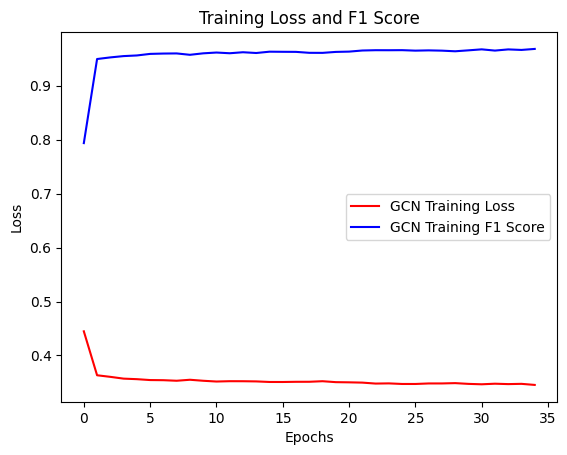

In [135]:
x = np.arange(EPOCHS_GCN, dtype=int)
plt.plot(x, train_losses, color="red", label="GCN Training Loss")
plt.plot(x, train_f1_scores, color="blue", label="GCN Training F1 Score")
plt.title("Training Loss and F1 Score")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [136]:
evaluate_gcn_model(gcn_model, graph_val_loader, vocab_size=vocab_size, device=device)

GCN performance:
Accuracy: 0.9155
Precision: 0.8206
Recall: 0.7662
F1 score: 0.7897
MCC: 0.5843


# Nuovo modello settando iperparametri differenti

` Modificati iperparametri col fine di migliorare le metriche del nuovo modello `


In [137]:
#device = get_device()
vocab_size = 342
hidden_dim = 256  # also the number of hidden nodes in the GCN. Can be set to 128, 256 or 512. If you have more GPU, you can increase it. However, you may face overfitting. Increase dropout if you face overfitting. Like dropout = 0.6, 0.7, 0.8
num_classes = 2
dropout = 0.7
output_dim = num_classes
# number of GCN layers, depending on your GPU, set it to any integer from 2 to 5.
num_layers = 4
EPOCHS_GCN = 100


device = torch.device("cuda")


gcn_model = GCNModel(
    in_channels=vocab_size,
    hidden_channels=hidden_dim,
    out_channels=num_classes,
    num_layers=num_layers,
    dropout=dropout,
).to(device)

train_losses, train_f1_scores = train_gcn_model(
    gcn_model,
    graph_train_loader,
    vocab_size=vocab_size,
    epochs=EPOCHS_GCN,
    device=device,
)

100%|██████████| 66/66 [00:01<00:00, 51.58it/s]


Epoch 1 / 100, Loss: 0.4464, F1 Score: 0.0590


100%|██████████| 66/66 [00:01<00:00, 49.74it/s]


Epoch 2 / 100, Loss: 0.4018, F1 Score: 0.5047


100%|██████████| 66/66 [00:00<00:00, 68.15it/s]


Epoch 3 / 100, Loss: 0.3931, F1 Score: 0.5838


... (190 outputs left out)

100%|██████████| 66/66 [00:00<00:00, 71.77it/s]


Epoch 99 / 100, Loss: 0.3566, F1 Score: 0.7952


100%|██████████| 66/66 [00:00<00:00, 72.82it/s]

Epoch 100 / 100, Loss: 0.3571, F1 Score: 0.7917


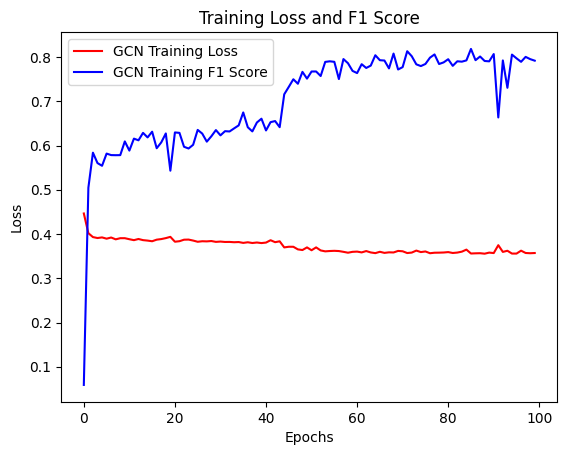

In [138]:
x = np.arange(EPOCHS_GCN, dtype=int)
plt.plot(x, train_losses, color="red", label="GCN Training Loss")
plt.plot(x, train_f1_scores, color="blue", label="GCN Training F1 Score")
plt.title("Training Loss and F1 Score")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [139]:
evaluate_gcn_model(gcn_model, graph_val_loader, vocab_size=vocab_size, device=device)

GCN performance:
Accuracy: 0.9541
Precision: 0.9038
Recall: 0.8820
F1 score: 0.8925
MCC: 0.7855


Modello con nuovi iperparametri e fake sample solo su train_data

In [167]:
data_1 = benign_train_sequences + benign_val_sequences + attack_sequences
labels_1 = benign_train_labels + benign_val_labels + attack_labels

# perform  70 % training and 30% testing set split

train_data_1, test_data_1, train_labels_1, test_labels_1 = train_test_split(
    data_1, labels_1, test_size=0.3, random_state=42, shuffle=True, stratify=labels_1
)
train_data_1 = train_data_1 + fake_samples.tolist()
train_labels_1 = train_labels_1 + fake_labels.tolist()

len(train_data_1), len(train_labels_1), len(test_data_1), len(test_labels_1)

(7286, 7286, 1786, 1786)

In [168]:
# Create a custom dataset
batch_size = 64
# convert train_data sequences and val_data sequences into graphs

train_graph_dataset_1 = fetch_graph_data(train_data_1, train_labels_1)
val_graph_dataset_1 = fetch_graph_data(test_data_1, test_labels_1)


# Create a data loader
graph_train_loader_1 = DataLoader(
    train_graph_dataset_1, batch_size=batch_size, shuffle=True
)
graph_val_loader_1 = DataLoader(val_graph_dataset_1, batch_size=batch_size, shuffle=False)

In [169]:
vocab_size = 342
hidden_dim = 256  # also the number of hidden nodes in the GCN. Can be set to 128, 256 or 512. If you have more GPU, you can increase it. However, you may face overfitting. Increase dropout if you face overfitting. Like dropout = 0.6, 0.7, 0.8
num_classes = 2
dropout = 0.7
output_dim = num_classes
# number of GCN layers, depending on your GPU, set it to any integer from 2 to 5.
num_layers = 4
EPOCHS_GCN = 100


device = torch.device("cuda")


gcn_model = GCNModel(
    in_channels=vocab_size,
    hidden_channels=hidden_dim,
    out_channels=num_classes,
    num_layers=num_layers,
    dropout=dropout,
).to(device)

train_losses, train_f1_scores = train_gcn_model(
    gcn_model,
    graph_train_loader_1,
    vocab_size=vocab_size,
    epochs=EPOCHS_GCN,
    device=device,
)

100%|██████████| 114/114 [00:01<00:00, 63.67it/s]


Epoch 1 / 100, Loss: 0.4293, F1 Score: 0.8286


100%|██████████| 114/114 [00:01<00:00, 57.41it/s]


Epoch 2 / 100, Loss: 0.3723, F1 Score: 0.9398


100%|██████████| 114/114 [00:01<00:00, 71.52it/s]


Epoch 3 / 100, Loss: 0.3659, F1 Score: 0.9469


... (190 outputs left out)

100%|██████████| 114/114 [00:01<00:00, 70.68it/s]


Epoch 99 / 100, Loss: 0.3416, F1 Score: 0.9702


100%|██████████| 114/114 [00:01<00:00, 70.46it/s]

Epoch 100 / 100, Loss: 0.3403, F1 Score: 0.9727


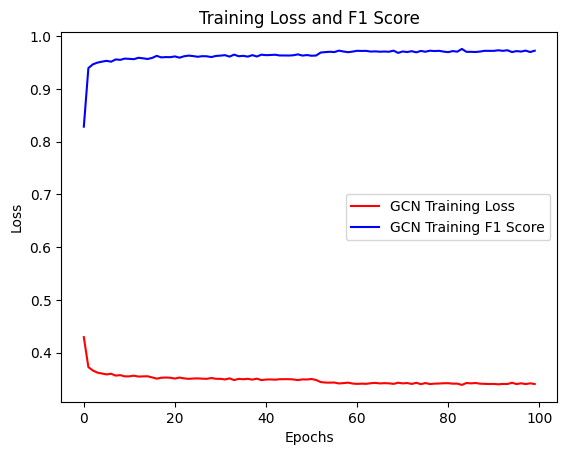

In [170]:
x = np.arange(EPOCHS_GCN, dtype=int)
plt.plot(x, train_losses, color="red", label="GCN Training Loss")
plt.plot(x, train_f1_scores, color="blue", label="GCN Training F1 Score")
plt.title("Training Loss and F1 Score")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [171]:
evaluate_gcn_model(gcn_model, graph_val_loader, vocab_size=vocab_size, device=device)

GCN performance:
Accuracy: 0.9462
Precision: 0.8681
Recall: 0.8985
F1 score: 0.8824
MCC: 0.7660


# Confronto grafico fake vs real

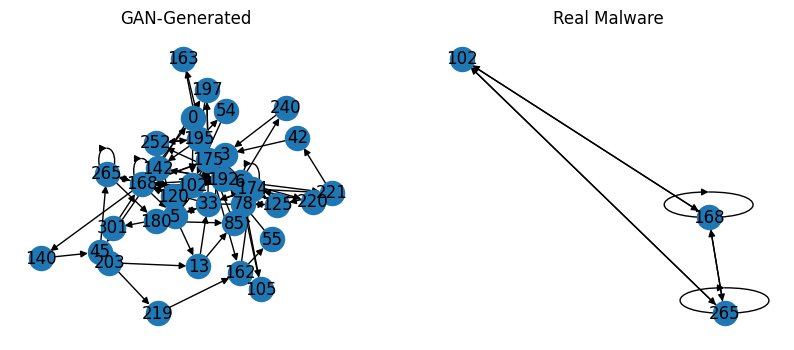

Fake vs Real (z-score):
-         average_degree: fake=     4.8 | mean=4.961323231245788 | std=1.3355113972028168 | z=-0.12079509885402266
-         avg_clustering: fake=0.15136260564831994 | mean=0.6442269678277107 | std=0.29781558161718663 | z=-1.6549314159556656
-        avg_betweenness: fake=0.042678889737713256 | mean=0.052681879185937704 | std=0.04207293082241071 | z=-0.23775356868878317
-                density: fake=0.1411764705882353 | mean=0.9358227823630955 | std=0.6982200399320899 | z=-1.1381029852024138
-               diameter: fake=       5 | mean=2.668900804289544 | std=1.526889678187629 | z=1.5266978544759033
-      avg_shortest_path: fake=2.4084033613445377 | mean=1.548705443763488 | std=0.556381875596567 | z=1.5451580205758129

Simile abbastanza? True  (tutte le metriche con |z| ≤ 2.0)


In [172]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# 1) Helpers semplici
def to_undirected_if_needed(G):
    return G if not G.is_directed() else G.to_undirected()

def analyze_graph(G: nx.Graph):
    """Ritorna un dizionario con poche metriche robuste e veloci."""
    U = to_undirected_if_needed(G)
    degs = [d for _, d in U.degree()]
    n = U.number_of_nodes()

    # valori None se grafo vuoto
    if n == 0:
        return dict(
            average_degree=None, avg_clustering=None, avg_betweenness=None,
            density=None, diameter=None, avg_shortest_path=None
        )

    metrics = {}
    metrics["average_degree"] = float(np.mean(degs))
    metrics["avg_clustering"] = float(np.mean(list(nx.clustering(U).values())))
    metrics["avg_betweenness"] = float(np.mean(list(nx.betweenness_centrality(U).values())))
    metrics["density"] = nx.density(U)

    # path-based solo se il grafo è connesso
    if nx.is_connected(U):
        metrics["diameter"] = nx.diameter(U)
        metrics["avg_shortest_path"] = nx.average_shortest_path_length(U)
    else:
        metrics["diameter"] = None
        metrics["avg_shortest_path"] = None

    return metrics

def mean_std_dict(list_of_metric_dicts):
    """Media e std per ogni metrica ignorando i None."""
    keys = list_of_metric_dicts[0].keys()
    means, stds = {}, {}
    for k in keys:
        vals = [d[k] for d in list_of_metric_dicts if d[k] is not None]
        means[k] = float(np.mean(vals)) if vals else None
        stds[k]  = float(np.std(vals, ddof=0)) if vals else None
    return means, stds

def z_scores(fake_metrics, means, stds):
    """Calcola z-score per ogni metrica (None se impossibile)."""
    z = {}
    for k, v in fake_metrics.items():
        mu, sd = means.get(k), stds.get(k)
        if (v is None) or (mu is None) or (sd is None) or (sd == 0):
            z[k] = None
        else:
            z[k] = (v - mu) / sd
    return z

# 2) Converte e disegna un fake vs un reale
gen_nx, _ = sequence_to_graph(fake_samples[0])
real_nx, _ = sequence_to_graph(attack_sequences[745])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); nx.draw(gen_nx, with_labels=True);  plt.title("GAN-Generated")
plt.subplot(1, 2, 2); nx.draw(real_nx, with_labels=True); plt.title("Real Malware")
plt.show()

# 3) Statistiche dei malware reali
real_graphs = [sequence_to_graph(seq)[0] for seq in attack_sequences]
real_metrics = [analyze_graph(g) for g in real_graphs]
means, stds  = mean_std_dict(real_metrics)

# 4) Metriche del fake e confronto con z-score
fake_metrics = analyze_graph(gen_nx)
z = z_scores(fake_metrics, means, stds)

Z_THR = 2.0  # soglia di similarità |z| <= Z_THR
similar_flags = {k: (abs(v) <= Z_THR) if (v is not None) else False for k, v in z.items()}
is_similar = all(similar_flags.values())

# Stampa compatta dei risultati
print("Fake vs Real (z-score):")
for k in fake_metrics.keys():
    print(f"- {k:>22s}: fake={fake_metrics[k]!s:>8} | mean={means[k]!s:>8} | std={stds[k]!s:>8} | z={z[k]}")
print(f"\nSimile abbastanza? {is_similar}  (tutte le metriche con |z| ≤ {Z_THR})")


# Conclusioni

Metriche sul test set (1786 tracce, di cui 224 attacchi). Precision, recall e F1 sono medie macro sulle due classi.

| Classificatore GCN | Training | Accuracy | Precision | Recall | F1 | MCC |
| --- | --- | --- | --- | --- | --- | --- |
| 3 layer, hidden 128, dropout 0,4, 35 epoche | solo dati reali | 0,9485 | 0,8903 | 0,8692 | 0,8794 | 0,7592 |
| 3 layer, hidden 128, dropout 0,4, 35 epoche | + 3121 attacchi sintetici | 0,9155 | 0,8206 | 0,7662 | 0,7897 | 0,5843 |
| 4 layer, hidden 256, dropout 0,7, 100 epoche | solo dati reali | 0,9541 | 0,9038 | 0,8820 | 0,8925 | 0,7855 |
| 4 layer, hidden 256, dropout 0,7, 100 epoche | + 3121 attacchi sintetici | 0,9462 | 0,8681 | 0,8985 | 0,8824 | 0,7660 |

I campioni sintetici peggiorano il classificatore in entrambe le configurazioni. La causa principale è l'addestramento della GAN. Questo notebook viene dalla versione 2024 del template, ma il codice clonato è quello di aprile 2025, in cui `train_gan_model` addestra solo il discriminatore per le prime 9 epoche (`warm_up_epochs=10` come valore predefinito). Quando il generatore comincia ad allenarsi, il discriminatore riconosce già i campioni finti quasi senza errori: la loss del generatore resta vicina a zero, i gradienti sono minimi e il generatore impara poco. Il confronto strutturale qui sopra usa un solo grafo generato e una soglia larga, quindi non basta a dire che i campioni sono realistici. L'analisi completa è nel README.